# Computation S — graded FANOUT as the rotation of a complex cost

**It from Bit via Gödel, Paper 1** · v2 material (2026-09-18) · companion to the FANOUT-boundary appendix and the redundancy ladder of the Wigner's-friend section · argument and ledger proposals in `knowledge/sessions/graded_fanout_complex_cost_2026-09-18T0830.md`

Paper 1 v1 says that erasure before FANOUT is thermodynamically free and that Landauer's
$kT\ln 2$ falls due when a record is written. The idea under test here is the replacement:
erasure before FANOUT has a **complex** cost, whose real part is the record and whose imaginary
part is the phase, and FANOUT is not a cut but the **rotation** of that cost from the imaginary
axis to the real one as the number of independent records grows.

**The model.** A system qubit $S$ in $(|0\rangle + |1\rangle)/\sqrt2$ is copied into $R$
environment fragments, one qubit each. Fragment $k$ is left in $|0\rangle$ if $S$ is $|0\rangle$
and taken to $|\epsilon_1^k\rangle = R_z(\theta_k)R_y(2\phi)|0\rangle$ if $S$ is $|1\rangle$: one
controlled $R_y$ and one controlled $R_z$ per fragment. The fragment overlap is then
$\lambda_k = \langle 0|\epsilon_1^k\rangle = e^{-i\theta_k/2}\cos\phi$, complex, with $\cos\phi$
the distinguishability (the record) and $\theta_k$ the phase the fragment imparts.

**The quantities.** After $R$ copies the coherence of $S$ is $\tfrac12\prod_k\overline{\lambda_k}$
(Zurek's decoherence factor), and the complex cost is its minus-log,

$$C_R = -\sum_k \ln\lambda_k, \qquad \mathrm{Re}\,C_R = \sum_k\ln\frac{1}{|\lambda_k|} = R\gamma,\qquad
\mathrm{Im}\,C_R = \tfrac12\sum_k\theta_k,$$

which is $i$ times the Feynman–Vernon influence action. Everything below is computed from the
circuit with `qiskit.quantum_info` and checked against these closed forms. Seed fixed; no
hidden state.


In [1]:
import math, cmath
import numpy as np
import matplotlib.pyplot as plt
import qiskit
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, partial_trace, entropy

SEED = 20260918
rng = np.random.default_rng(SEED)

PHI = 0.30      # distinguishability angle: |lambda| = cos(PHI)
SIGMA = 0.50    # spread of the fragment phases theta_k ~ N(0, SIGMA)
LN2 = math.log(2.0)
GAMMA = -math.log(math.cos(PHI))

print("qiskit", qiskit.__version__)
print("per-copy real cost gamma = -ln cos(phi) = %.6f nat, |lambda| = %.6f" % (GAMMA, math.cos(PHI)))


qiskit 2.5.2
per-copy real cost gamma = -ln cos(phi) = 0.045692 nat, |lambda| = 0.955336


## 1. The circuit and the closed forms

Qubit 0 is $S$; qubits $1\ldots R$ are the fragments. `cry(2*phi)` sets the distinguishability,
`crz(theta_k)` the phase. Both are controlled on $S$, so nothing happens to a fragment in the
$|0\rangle$ branch.

In [2]:
def branching_circuit(thetas, phi=PHI):
    R = len(thetas)
    qc = QuantumCircuit(1 + R)
    qc.h(0)
    for k, th in enumerate(thetas):
        qc.cry(2 * phi, 0, k + 1)
        qc.crz(th, 0, k + 1)
    return qc

def overlaps(thetas, phi=PHI):
    return [cmath.exp(-1j * th / 2) * math.cos(phi) for th in thetas]

def complex_cost(thetas, phi=PHI):
    return -sum(cmath.log(l) for l in overlaps(thetas, phi))

def rho_S(qc):
    sv = Statevector(qc)
    return partial_trace(sv, list(range(1, qc.num_qubits)))

thetas3 = rng.normal(0.0, SIGMA, size=3)
qc3 = branching_circuit(thetas3)
print(qc3.draw(output="text"))
rho = rho_S(qc3)
D = np.prod([l.conjugate() for l in overlaps(thetas3)])
print("coherence rho_S(0,1) from the circuit : %.6f%+.6fi" % (rho.data[0, 1].real, rho.data[0, 1].imag))
print("closed form (1/2) prod conj(lambda_k)  : %.6f%+.6fi" % ((0.5 * D).real, (0.5 * D).imag))
print("S(rho_S) from the circuit (nats)      : %.6f" % entropy(rho, base=math.e))
C = complex_cost(thetas3)
print("complex cost C_3 = %.4f %+.4fi  (Re = 3*gamma = %.4f)" % (C.real, C.imag, 3 * GAMMA))


     ┌───┐                                                                »
q_0: ┤ H ├─────■────────────■─────────────■────────────■────────────■─────»
     └───┘┌────┴────┐┌──────┴───────┐     │            │            │     »
q_1: ─────┤ Ry(0.6) ├┤ Rz(-0.73829) ├─────┼────────────┼────────────┼─────»
          └─────────┘└──────────────┘┌────┴────┐┌──────┴──────┐     │     »
q_2: ────────────────────────────────┤ Ry(0.6) ├┤ Rz(0.53828) ├─────┼─────»
                                     └─────────┘└─────────────┘┌────┴────┐»
q_3: ──────────────────────────────────────────────────────────┤ Ry(0.6) ├»
                                                               └─────────┘»
«                     
«q_0: ───────■────────
«            │        
«q_1: ───────┼────────
«            │        
«q_2: ───────┼────────
«     ┌──────┴───────┐
«q_3: ┤ Rz(-0.10848) ├
«     └──────────────┘
coherence rho_S(0,1) from the circuit : 0.430777-0.066978i
closed form (1/2) prod conj(lambda_k)  : 0.430777-

## 2. The rotation: real part accumulates, imaginary part random-walks

With independent fragment phases, $\mathrm{Re}\,C_R = R\gamma$ grows linearly while
$\mathrm{Im}\,C_R = \tfrac12\sum\theta_k$ is a random walk of size $\sigma\sqrt{R/(2\pi)}\cdot\sqrt{\pi}$
$\approx \tfrac{\sigma}{2}\sqrt{2R/\pi}$, so the angle of the cost from the real axis falls as
$1/\sqrt R$. With identical phases the imaginary part grows as $R\theta/2$ and the angle never
moves: a coherent (replica) environment does not rotate the cost. The system's entropy saturates
at the Landauer value $\ln 2$ while the real cost keeps growing; the surplus is redundancy.

In [3]:
print(" R   Re C      Im C(rand)  arg(rand)  |D_R|      S/ln2     Im C(same)  arg(same)")
thetas_all = rng.normal(0.0, SIGMA, size=12)
for R in range(1, 13):
    th = thetas_all[:R]
    qc = branching_circuit(th)
    rho = rho_S(qc)
    Dabs = abs(rho.data[0, 1]) * 2
    C = complex_cost(th)
    C_same = complex_cost([SIGMA] * R)
    print("%2d  %7.4f  %9.4f  %8.4f  %9.3e  %7.4f  %9.3f  %8.4f"
          % (R, C.real, C.imag, math.atan2(C.imag, C.real), Dabs,
             entropy(rho, base=math.e) / LN2, C_same.imag, math.atan2(C_same.imag, C_same.real)))

# Ensemble statement of the random walk (closed form; no circuits needed)
trials = 4000
print("\nE|Im C_R| over %d phase draws, against (sigma/2) sqrt(2R/pi), and E|Im C|/Re C ~ 1/sqrt(R):" % trials)
for R in (16, 64, 256, 1024):
    ims = np.abs(0.5 * rng.normal(0.0, SIGMA, size=(trials, R)).sum(axis=1))
    print("  R=%4d  E|Im C| = %.3f  (predicted %.3f)   E|Im C|/Re C = %.4f"
          % (R, ims.mean(), 0.5 * SIGMA * math.sqrt(2 * R / math.pi), ims.mean() / (R * GAMMA)))


 R   Re C      Im C(rand)  arg(rand)  |D_R|      S/ln2     Im C(same)  arg(same)
 1   0.0457     0.1486    1.2724  9.553e-01   0.1543      0.250    1.3900
 2   0.0914     0.4302    1.3615  9.127e-01   0.2589      0.500    1.3900
 3   0.1371     0.0600    0.4125  8.719e-01   0.3433      0.750    1.3900
 4   0.1828    -0.2203   -0.8782  8.330e-01   0.4145      1.000    1.3900
 5   0.2285    -0.1617   -0.6159  7.958e-01   0.4757      1.250    1.3900
 6   0.2741    -0.2441   -0.7275  7.602e-01   0.5290      1.500    1.3900
 7   0.3198    -0.2186   -0.5995  7.263e-01   0.5760      1.750    1.3900
 8   0.3655    -0.1875   -0.4740  6.938e-01   0.6175      2.000    1.3900
 9   0.4112    -0.0823   -0.1975  6.628e-01   0.6544      2.250    1.3900
10   0.4569    -0.0455   -0.0993  6.332e-01   0.6874      2.500    1.3900
11   0.5026    -0.0710   -0.1404  6.050e-01   0.7169      2.750    1.3900
12   0.5483    -0.1951   -0.3419  5.779e-01   0.7435      3.000    1.3900

E|Im C_R| over 4000 phase draw

## 3. Not a cut: a single copy already has a real part

Only a fragment with $|\lambda| = 1$, one that carries no which-branch information, has a purely
imaginary cost. Any distinguishability at all, even at $R = 1$, has a real part. "Pre-FANOUT"
therefore has an exact definition, $|\lambda_k| = 1$ for every fragment, and the boundary is
graded from the first copy.

In [4]:
print(" phi    |lambda|   Re C_1 (nat)   S(rho_S)/ln2 after one copy")
for phi in (0.0, 0.05, 0.1, 0.3, 0.6, 1.0, 1.4):
    qc = branching_circuit([SIGMA], phi=phi)
    rho = rho_S(qc)
    print(" %.2f   %.4f     %.5f       %.5f" % (phi, math.cos(phi), -math.log(math.cos(phi)), entropy(rho, base=math.e) / LN2))


 phi    |lambda|   Re C_1 (nat)   S(rho_S)/ln2 after one copy
 0.00   1.0000     -0.00000       0.00000
 0.05   0.9988     0.00125       0.00755
 0.10   0.9950     0.00501       0.02519
 0.30   0.9553     0.04569       0.15434
 0.60   0.8253     0.19197       0.42750
 1.00   0.5403     0.61563       0.77775
 1.40   0.1700     1.77215       0.97906


## 4. Zurek's plateau: the real part is redundancy, the phase is what fails to proliferate

The mutual information $I(S{:}F_f) = S(\rho_S) + S(\rho_F) - S(\rho_{SF})$ between $S$ and a set
$F$ of $f$ fragments rises to the plateau $H_S$ and exceeds it only when nearly all fragments are
held: the pointer information is redundant, the phase information is not. This is the exact sense
in which the imaginary part is "paid at the cut" — conserved globally, available locally to no
one. Two distinguishabilities are shown: weak fragments ($\phi = 0.3$) need many of themselves to
reach the plateau; strong ones ($\phi = 1.0$) reach it almost at once.

phi=0.3  I(S:F_f)/H_S for f=0..10: 0.00 0.27 0.48 0.66 0.83 1.00 1.17 1.34 1.52 1.73 2.00


phi=1.0  I(S:F_f)/H_S for f=0..10: 0.00 0.78 0.94 0.98 1.00 1.00 1.00 1.02 1.06 1.22 2.00


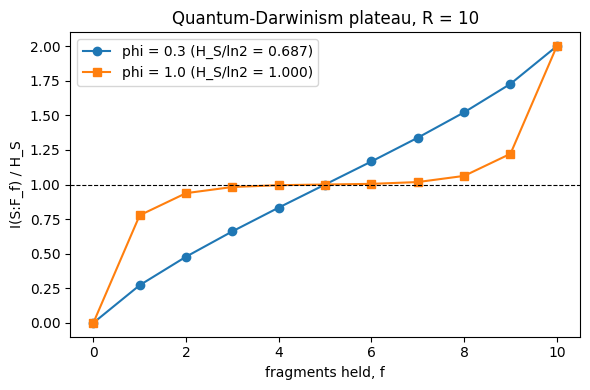

In [5]:
def mutual_information_curve(R, phi):
    thetas = rng.normal(0.0, SIGMA, size=R)
    sv = Statevector(branching_circuit(thetas, phi=phi))
    n = R + 1
    S_S = entropy(partial_trace(sv, list(range(1, n))), base=math.e)
    out = []
    for f in range(0, R + 1):
        F = list(range(1, 1 + f))
        rest = [q for q in range(1, n) if q not in F]
        S_F = entropy(partial_trace(sv, [0] + rest), base=math.e) if f > 0 else 0.0
        S_SF = entropy(partial_trace(sv, rest), base=math.e) if rest else 0.0
        out.append(S_S + S_F - S_SF)
    return np.array(out), S_S

R = 10
fig, ax = plt.subplots(figsize=(6, 4))
for phi, style in ((0.3, "o-"), (1.0, "s-")):
    I, HS = mutual_information_curve(R, phi)
    ax.plot(range(R + 1), I / HS, style, label="phi = %.1f (H_S/ln2 = %.3f)" % (phi, HS / LN2))
    print("phi=%.1f  I(S:F_f)/H_S for f=0..%d:" % (phi, R), " ".join("%.2f" % x for x in I / HS))
ax.axhline(1.0, color="k", lw=0.8, ls="--")
ax.set_xlabel("fragments held, f"); ax.set_ylabel("I(S:F_f) / H_S")
ax.set_title("Quantum-Darwinism plateau, R = %d" % R); ax.legend()
plt.tight_layout(); plt.show()


## 5. The objection, and its answer: the phase is relative, and unobservability is the cost

*If the deletion only changes a phase, and the global phase is unobservable, the deletion is
free in practice.* The imaginary cost is not a global phase. Phase-only copies ($\phi = 0$)
impart $e^{-i\theta_k/2}$ to the $|1\rangle$ branch of $S$ relative to the $|0\rangle$ branch, and
an $X$-basis measurement of $S$ reads it: $P(+) = \tfrac12\bigl(1 + \cos\tfrac12\sum_k\theta_k\bigr)$.
Applying the inverse phases restores $P(+) = 1$: reversible, not dissipative. And **averaging over
untracked phases** reproduces decoherence exactly: $E\,e^{i\Sigma\theta/2} = e^{-R\sigma^2/8}$.
Declaring the phase inaccessible is what converts the imaginary cost into the real one; Landauer's
toll is incurred by the inaccessibility, not by the unitary.

In [6]:
from qiskit_aer import AerSimulator
sim = AerSimulator(seed_simulator=SEED)

R = 6

def p_plus_after(thetas, undo=False, shots=20000):
    # phase-only copies (phi = 0), optionally undone, then S read in the X basis
    qc = branching_circuit(thetas, phi=0.0)
    if undo:
        for k, t in enumerate(thetas):
            qc.crz(-t, 0, k + 1)
    qc.h(0)
    qc.measure_all()
    counts = sim.run(qc, shots=shots).result().get_counts()
    return sum(v for k, v in counts.items() if k[-1] == "0") / shots   # qubit 0 is the last character

for label, th in (("random phases", rng.normal(0.0, SIGMA, size=R)), ("chosen phases theta_k = 1", np.full(R, 1.0))):
    half_sum = 0.5 * th.sum()
    print("%s: sum theta/2 = %.4f" % (label, half_sum))
    print("   P(+) measured = %.4f, formula (1+cos(sum theta/2))/2 = %.4f"
          % (p_plus_after(th), 0.5 * (1 + math.cos(half_sum))))
    print("   after applying the inverse phases: P(+) measured = %.4f  (reversible: expected 1)" % p_plus_after(th, undo=True))

# untracked phases: average the coherence over draws -> decoherence
draws = 3000
coh = np.mean([np.exp(0.5j * rng.normal(0.0, SIGMA, size=R).sum()) for _ in range(draws)])
print("coherence averaged over %d untracked draws: |E e^{i sum theta/2}| = %.4f, formula e^{-R sigma^2/8} = %.4f"
      % (draws, abs(coh), math.exp(-R * SIGMA ** 2 / 8)))


random phases: sum theta/2 = -0.0078
   P(+) measured = 1.0000, formula (1+cos(sum theta/2))/2 = 1.0000
   after applying the inverse phases: P(+) measured = 1.0000  (reversible: expected 1)
chosen phases theta_k = 1: sum theta/2 = 3.0000
   P(+) measured = 0.0053, formula (1+cos(sum theta/2))/2 = 0.0050
   after applying the inverse phases: P(+) measured = 1.0000  (reversible: expected 1)
coherence averaged over 3000 untracked draws: |E e^{i sum theta/2}| = 0.8257, formula e^{-R sigma^2/8} = 0.8290


In [7]:
# --- the same phase-only test on a real device -------------------------------
# A demonstration, not a second proof: the Aer cell above is the reproducible
# claim. Needs qiskit-ibm-runtime and a saved account; see notebooks/README.md.
import datetime
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2

R_HW, TH_HW, SHOTS_HW = 6, 1.0, 20000

def hw_circuit(undo=False):
    qc = QuantumCircuit(R_HW + 1, 1)
    qc.h(0)
    for k in range(R_HW):
        qc.cry(0.0, 0, k + 1)      # phi = 0: phase only, no distinguishability
        qc.crz(TH_HW, 0, k + 1)
    if undo:
        for k in range(R_HW):
            qc.crz(-TH_HW, 0, k + 1)
    qc.h(0)
    qc.measure(0, 0)
    return qc

service = QiskitRuntimeService()
backend = service.backend("ibm_marrakesh")
pm = generate_preset_pass_manager(optimization_level=1, backend=backend)

isa = {tag: pm.run(hw_circuit(undo)) for tag, undo in (("forward", False), ("reversed", True))}
sampler = SamplerV2(mode=backend)
job = sampler.run([isa["forward"], isa["reversed"]], shots=SHOTS_HW)
print("backend %s   job %s   %s UTC" % (backend.name, job.job_id(),
                                        datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d %H:%M")))
result = job.result()

half_sum = 0.5 * R_HW * TH_HW
print("sum theta/2 = %.4f, shots = %d" % (half_sum, SHOTS_HW))
for i, tag in enumerate(("forward", "reversed")):
    counts = result[i].data.c.get_counts()
    p_plus = counts.get("0", 0) / SHOTS_HW
    expected = 0.5 * (1 + math.cos(half_sum)) if tag == "forward" else 1.0
    print("  %-8s depth %3d, %2d two-qubit gates: P(+) measured = %.4f   formula = %.4f   shortfall = %+.4f"
          % (tag, isa[tag].depth(),
             sum(1 for ins in isa[tag].data if ins.operation.num_qubits == 2),
             p_plus, expected, p_plus - expected))


backend ibm_marrakesh   job dao3stopqrnc7399f8vg   2026-09-20 20:13 UTC


sum theta/2 = 3.0000, shots = 20000
  forward  depth  72, 21 two-qubit gates: P(+) measured = 0.1270   formula = 0.0050   shortfall = +0.1219
  reversed depth 138, 48 two-qubit gates: P(+) measured = 0.7855   formula = 1.0000   shortfall = -0.2145


The device does not reach either figure, and the gap is the point. Every
controlled rotation is a physical two-qubit gate on a machine with finite
coherence, so some of the phase leaks into the environment of the device itself
before the final $H$ can bring it back. That leakage is a real cost, paid to an
environment the model does not carry: the model's fragments are the only
environment it knows about, and it assumes the copies are otherwise perfect.
The simulator, which has no such environment, returns the closed forms. The
difference between the two cells is the size of the term that has been left
out.

## 6. What this notebook establishes

- **STRUCTURAL.** The complex cost $C_R = -\sum_k\ln\lambda_k$ of copying into fragments has real
  part the record and imaginary part the phase; it is computed here from circuits and matches the
  closed forms. It is $i$ times the Feynman–Vernon influence action.
- **STRUCTURAL.** With independent fragments the cost rotates from the imaginary to the real axis
  with angle $\sim 1/\sqrt R$; with identical fragments it does not rotate. There is no sharp cut:
  any distinguishability gives a real part at $R = 1$; pre-FANOUT is exactly $|\lambda| = 1$.
- **STRUCTURAL.** The system's entropy saturates at Landauer's value while the real cost grows as
  redundancy; the phase information needs nearly all fragments (Zurek's plateau).
- **STRUCTURAL.** The imaginary cost is a relative phase, observable by interference and
  reversible; averaging over untracked phases converts it into the real cost. Unobservability is
  not freedom; it is the payment.
- **CANDIDATE.** At imaginary inverse temperature the Caldeira–Leggett noise kernel is a phase
  ($\coth(ix) = -i\cot x$), Hawking's CTC bath; the rotation above is his rotation of $1/T$ with
  the angle supplied by the redundancy. See the session note for the fences.
